# Disease Prediction Model
Predict whether a breast tumor is malignant or benign using patient medical data.


In [36]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer(as_frame=True)
df = data.frame
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Dataset: Breast Cancer Wisconsin dataset (scikit-learn)

In [37]:
print(df.shape)
print(df.isnull().sum().sum())
print(df["target"].value_counts())
df.info()

(569, 31)
0
target
1    357
0    212
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error       

Observations:
The data is composed of 569 data samples and 31 features (columns) and 1 target (label).
There are no missing values and all the columns are numeric.
The data is somewhat skewed because there are more benign cases than malignant, with 357 benign cases and 212 malignant cases.
In the original data the classes were malignant (0) and benign (1), so I changed that to make malignant = 1.

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

y = (df["target"] == 0).astype(int)

X = df.drop("target", axis=1)

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape, X_test.shape)
print(y.value_counts())

(455, 30) (114, 30)
target
0    357
1    212
Name: count, dtype: int64


Data preparation:
 Target: malignant = 1, benign = 0.
  Data split into 80% training and 20% testing, keeping the class ratio the same.
StandardScaler has been used to scale the features due to the sensitivity of the models such as Logistic Regression and SVM to feature ranges.

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
log_model = LogisticRegression(max_iter=5000)
log_model.fit(X_train, y_train)
log_pred = log_model.predict(X_test)

print("Logistic Regression accuracy:", accuracy_score(y_test, log_pred))

Logistic Regression accuracy: 0.9649122807017544


In [40]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest accuracy:", accuracy_score(y_test, rf_pred))

Random Forest accuracy: 0.9736842105263158


In [41]:
from sklearn.svm import SVC

svm_model = SVC(probability=True, random_state=42)
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)

print("SVM accuracy:", accuracy_score(y_test, svm_pred))

SVM accuracy: 0.9736842105263158


Model training:
I trained all three classification algorithms (SVM, Logistic Regression and Random Forest) as suggested in the task.
Logistic Regression is a simple and quick model that is easy to explain.
 Random Forest is made of a bunch of decision trees and votes on them, thus is usually correct and less prone to overfitting.
 SVM calculates the separating boundary for the two classes with the maximum separation and it performs better on numeric data that has been scaled.
 80% of the data was used for training and 20% for testing for each model.
In medical prediction, recall is really crucial, missing a malignant case is costly, so I am going to look at precision, recall, F1-score and ROC-AUC next.

In [42]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

print("Precision:", precision_score(y_test, log_pred))
print("Recall:", recall_score(y_test, log_pred))
print("F1-Score:", f1_score(y_test, log_pred))

log_prob = log_model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, log_prob))

Precision: 0.975
Recall: 0.9285714285714286
F1-Score: 0.9512195121951219
ROC-AUC: 0.996031746031746


In [43]:
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1-Score:", f1_score(y_test, rf_pred))

rf_prob = rf_model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

Precision: 1.0
Recall: 0.9285714285714286
F1-Score: 0.9629629629629629
ROC-AUC: 0.9928902116402116


In [44]:
print("Precision:", precision_score(y_test, svm_pred))
print("Recall:", recall_score(y_test, svm_pred))
print("F1-Score:", f1_score(y_test, svm_pred))

svm_prob = svm_model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, svm_prob))

Precision: 1.0
Recall: 0.9285714285714286
F1-Score: 0.9629629629629629
ROC-AUC: 0.9947089947089947


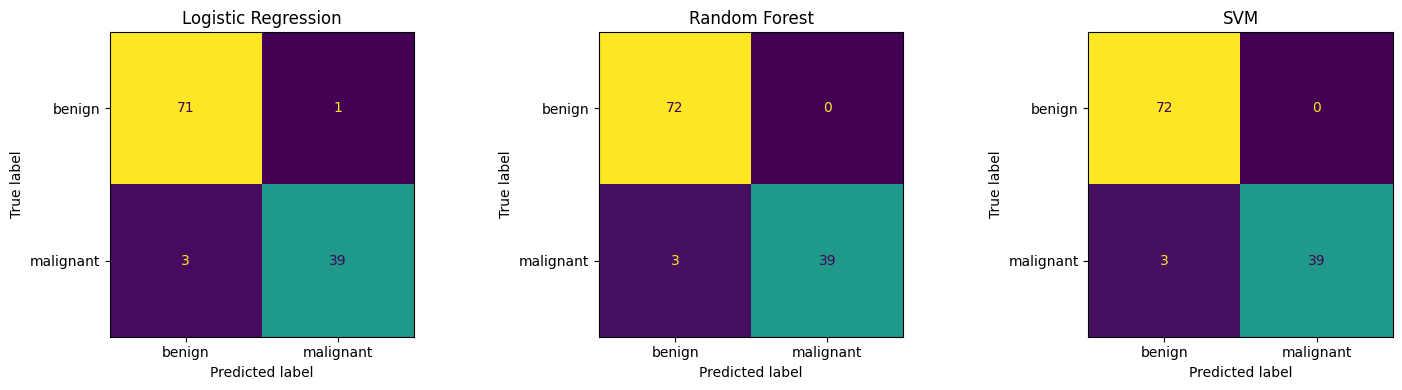

In [45]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pred) in zip(axes, [("Logistic Regression", log_pred),
                                    ("Random Forest", rf_pred),
                                    ("SVM", svm_pred)]):
    cmd = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cmd, display_labels=["benign", "malignant"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

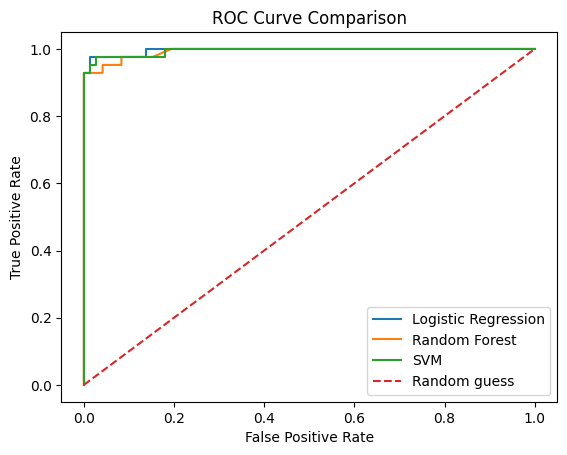

In [46]:
from sklearn.metrics import roc_curve

plt.figure()

for name, prob in [("Logistic Regression", log_prob),
                   ("Random Forest", rf_prob),
                   ("SVM", svm_prob)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], "--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

Model evaluation:
 Logistic Regression: Precision 0.975, Recall 0.929, F1 0.951, ROC-AUC 0.996
 Random Forest: Precision 1.000, Recall 0.929, F1 0.963, ROC-AUC 0.993
 SVM: Precision 1.000, Recall 0.929, F1 0.963, ROC-AUC 0.995
All three models worked very well, as the two classes in this dataset were separable.
Both Random Forest and SVM led to no false alarms (precision 1.0) and were also found to have the same F1 score. The sensitivity/ROC-AUC of SVM was slightly higher, so I chose SVM as the final model.
All three models had recall that was the same; each of them failed to recall 3 of 42 malignant cases. The primary limitation is failing to identify a malignant case in medical prediction, which can be expensive.
The test set is small (114 cases) and the differences between the models must not be interpreted too much.
 Final choice: SVM.